# Notebook 04: Stylized Facts

**Paper Reference:** Gould et al. (2013), Section 4 — *Empirical observations in LOBs*

This notebook walks through empirical regularities ("stylized facts") reported across many LOB markets and the statistical tools used to measure them. Sections 1–3 and 6–9 use synthetic data with the property built in, to show what each measurement looks like when the effect is known to be there. Sections 4, 5 and 10 measure the simulation models from the other notebooks.

The stylized facts we cover:
1. Heavy-tailed order sizes
2. Order size clustering at round numbers
3. Power-law distributed relative prices
4. Hump-shaped depth profiles
5. Concave price impact
6. Heavy-tailed return distributions
7. Volatility clustering
8. Long memory, and how hard it is to measure
9. Long memory in order signs
10. Negative short-lag autocorrelation and the bid-ask bounce

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from lob.order import reset_order_id_counter
from lob.simulation import Simulation, SimulationConfig
from lob.models.zero_intelligence import SmithFarmerModel
from lob.models.mike_farmer import MikeFarmer2008Model, MikeFarmerModel, _generate_fractional_noise
from lob.models.strategic import ParlourModel
from lob.metrics import mean_virtual_impact
from lob.analysis.stylized_facts import (
    fit_power_law, compute_acf, compute_hurst_rs, hill_estimator,
    compute_volatility_clustering, compute_order_sign_acf, fit_loglog_slope,
    mean_depth_profile, classify_depth_profile, white_noise_band,
)
from lob.analysis.plotting import set_style, plot_return_distribution, plot_acf, plot_price_impact

set_style()
pd.set_option('display.max_colwidth', None)
rng = np.random.default_rng(42)


def run_model(model, n_events, seed=42, warmup=5_000, snapshot_interval=None):
    """Run a model and return (simulation, event log)."""
    reset_order_id_counter()
    config = SimulationConfig(n_events=n_events, warmup_events=warmup, seed=seed,
                              record_book_snapshots=snapshot_interval is not None,
                              snapshot_interval=snapshot_interval or 100)
    sim = Simulation(model=model, config=config)
    return sim, sim.run(progress=False)

## 1. Heavy-Tailed Order Sizes

From the paper (Section 4.1): *"it is unsurprising that incoming order sizes vary substantially. Nevertheless, several regularities occur in empirical data."* For two NASDAQ stocks, for example, Maslov and Mills (2001) fitted both power-law and log-normal distributions to the sizes of incoming limit orders.

Below we draw log-normal order sizes: most orders are small, but very large ones are far more common than a normal distribution would allow.

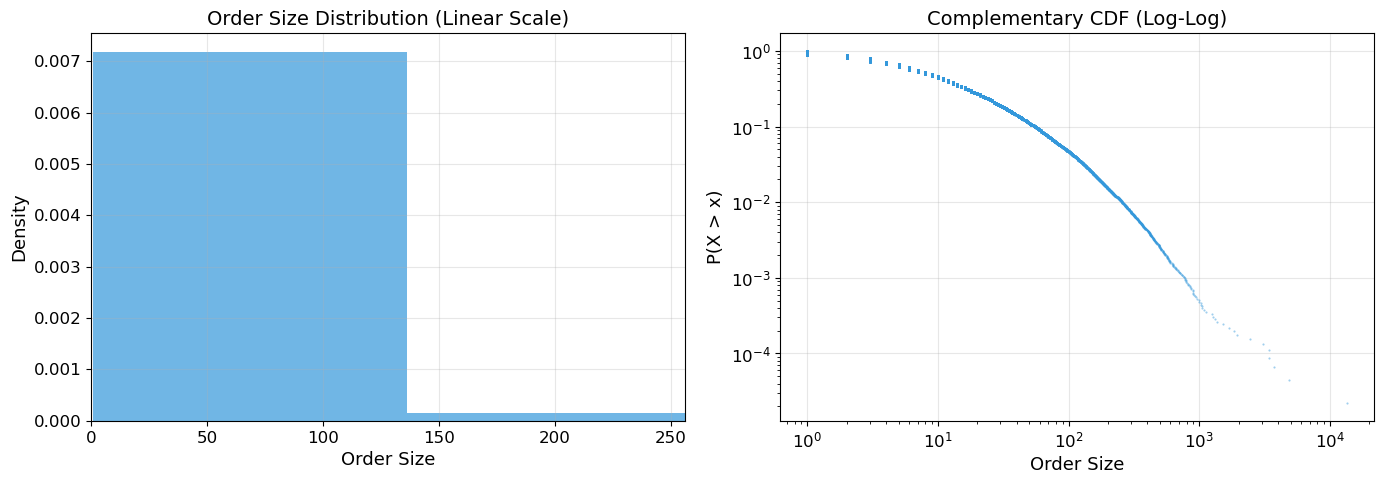

Power-law fit to the tail above xmin = 256 (457 orders): density exponent 3.05, so P(size > x) falls off like x^-2.05
The largest order is 1,688 times the median order


In [2]:
order_sizes = np.exp(rng.normal(2.0, 1.5, size=50000)).astype(int)
order_sizes = order_sizes[order_sizes > 0]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Linear scale
axes[0].hist(order_sizes, bins=100, density=True, alpha=0.7, color='#3498db')
axes[0].set_xlabel('Order Size')
axes[0].set_ylabel('Density')
axes[0].set_title('Order Size Distribution (Linear Scale)')
axes[0].set_xlim(0, np.percentile(order_sizes, 99))

# Log-log scale (CCDF)
sorted_sizes = np.sort(order_sizes)[::-1]
ccdf = np.arange(1, len(sorted_sizes) + 1) / len(sorted_sizes)
axes[1].loglog(sorted_sizes, ccdf, '.', markersize=1, alpha=0.5, color='#3498db')
axes[1].set_xlabel('Order Size')
axes[1].set_ylabel('P(X > x)')
axes[1].set_title('Complementary CDF (Log-Log)')

plt.tight_layout()
plt.show()

result = fit_power_law(order_sizes.astype(float))
print(f"Power-law fit to the tail above xmin = {result['xmin']:.0f} ({result['n_tail']:,} orders): "
      f"density exponent {result['alpha']:.2f}, so P(size > x) falls off like x^-{result['alpha'] - 1:.2f}")
print(f"The largest order is {order_sizes.max() / np.median(order_sizes):,.0f} times the median order")

## 2. Order Size Clustering

From the paper (Section 4.1), on the Island ECN, Challet and Stinchcombe (2001) reported that incoming limit *"order sizes $|\omega_x|$ clustered strongly at round-number amounts such as 10, 100, and 1000."*

We simulate traders who round some of their orders to multiples of 5, 10 or 100.

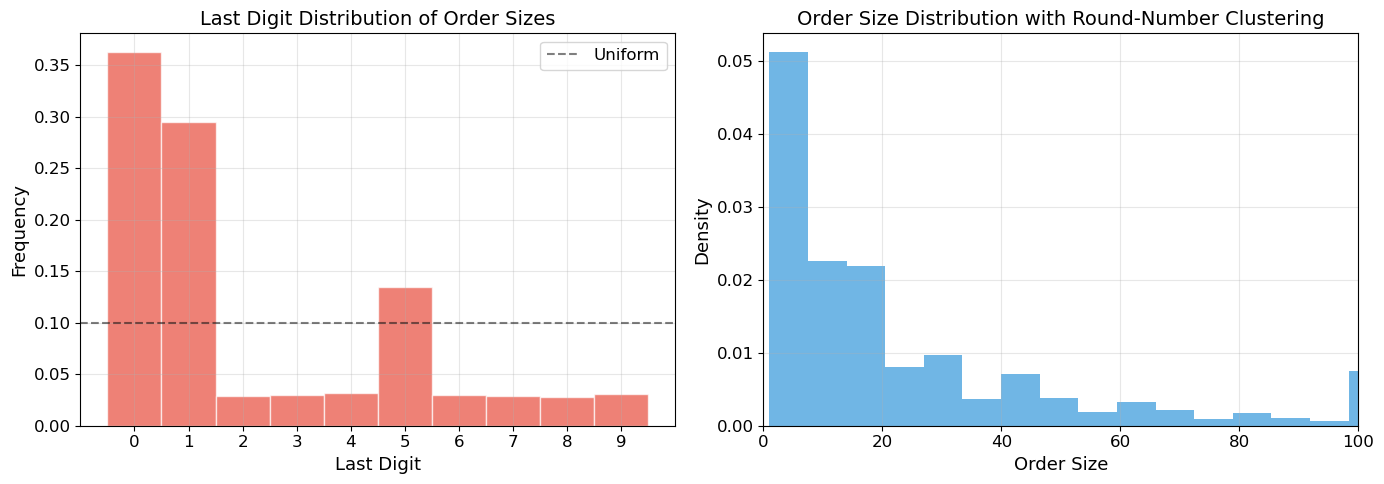

49.8% of orders are multiples of 5 (20% expected without rounding)
36.3% of orders are multiples of 10 (10% expected without rounding)


In [3]:
n = 10000
base_sizes = rng.lognormal(3, 1, n).astype(int) + 1

# Round 70% of orders: 30% to the nearest 100, 20% to the nearest 10, 20% to the nearest 5
clustered = base_sizes.copy()
for i in range(n):
    r = rng.random()
    if r < 0.3:
        clustered[i] = max(1, round(base_sizes[i] / 100) * 100)
    elif r < 0.5:
        clustered[i] = max(1, round(base_sizes[i] / 10) * 10)
    elif r < 0.7:
        clustered[i] = max(1, round(base_sizes[i] / 5) * 5)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribution of last digit
last_digits = clustered % 10
axes[0].hist(last_digits, bins=range(11), density=True, alpha=0.7,
             color='#e74c3c', edgecolor='white', align='left')
axes[0].set_xlabel('Last Digit')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Last Digit Distribution of Order Sizes')
axes[0].set_xticks(range(10))
axes[0].axhline(y=0.1, color='black', linestyle='--', alpha=0.5, label='Uniform')
axes[0].legend()

# Histogram with spikes at round numbers
axes[1].hist(clustered, bins=200, density=True, alpha=0.7, color='#3498db')
axes[1].set_xlabel('Order Size')
axes[1].set_ylabel('Density')
axes[1].set_title('Order Size Distribution with Round-Number Clustering')
axes[1].set_xlim(0, np.percentile(clustered, 95))

plt.tight_layout()
plt.show()

pct_div5 = np.mean(clustered % 5 == 0) * 100
pct_div10 = np.mean(clustered % 10 == 0) * 100
print(f"{pct_div5:.1f}% of orders are multiples of 5 (20% expected without rounding)")
print(f"{pct_div10:.1f}% of orders are multiples of 10 (10% expected without rounding)")

## 3. Power-Law Relative Prices

From the paper (Section 4.2): *"Several authors have reported power-law behaviour in the distribution of relative prices."* The reported exponents vary by market: about 0.6 on the Paris Bourse, about 1.5 on the LSE, and 1.72 for buy orders and 1.15 for sell orders on the Shenzhen Stock Exchange.

A note on conventions: `fit_power_law` follows Clauset et al. (2009) and returns the exponent $\alpha$ of the *density*, $p(x) \propto x^{-\alpha}$. The complementary CDF then falls off as $P(X > x) \propto x^{-(\alpha - 1)}$. We generate relative prices whose complementary CDF falls off as $x^{-1.5}$, so the fit should return $\alpha \approx 2.5$.

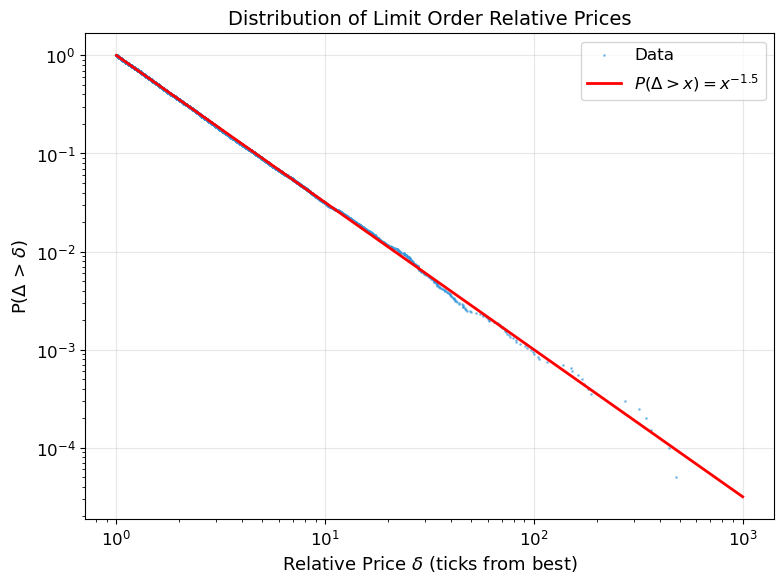

Generated with a CCDF exponent of 1.5, so the expected density exponent is 2.5
Fitted density exponent: 2.51 (xmin = 1.0), implying a CCDF exponent of 1.51
The fit recovers the exponent used to generate the data.


In [4]:
ccdf_exponent = 1.5
xmin = 1.0
u = rng.random(20000)
relative_prices = xmin * u ** (-1.0 / ccdf_exponent)
relative_prices = relative_prices[relative_prices < 1000]  # trim extremes

result = fit_power_law(relative_prices)

fig, ax = plt.subplots(figsize=(8, 6))
sorted_rp = np.sort(relative_prices)[::-1]
ccdf = np.arange(1, len(sorted_rp) + 1) / len(sorted_rp)
ax.loglog(sorted_rp, ccdf, '.', markersize=2, alpha=0.5, color='#3498db', label='Data')
x_ref = np.logspace(0, 3, 100)
ax.loglog(x_ref, (xmin / x_ref) ** ccdf_exponent, 'r-', linewidth=2,
          label=f'$P(\\Delta > x) = x^{{-{ccdf_exponent}}}$')
ax.set_xlabel('Relative Price $\\delta$ (ticks from best)')
ax.set_ylabel('P($\\Delta$ > $\\delta$)')
ax.set_title('Distribution of Limit Order Relative Prices')
ax.legend()
plt.tight_layout()
plt.show()

expected = ccdf_exponent + 1
print(f"Generated with a CCDF exponent of {ccdf_exponent}, so the expected density exponent is {expected}")
print(f"Fitted density exponent: {result['alpha']:.2f} (xmin = {result['xmin']:.1f}), "
      f"implying a CCDF exponent of {result['alpha'] - 1:.2f}")
recovered = abs(result['alpha'] - expected) < 0.1
print("The fit recovers the exponent used to generate the data." if recovered else
      "The fit misses the exponent used to generate the data by more than 0.1.")

## 4. Hump-Shaped Depth Profile

From the paper (Section 4.4): *"Mean relative depth profiles have been reported to exhibit a hump shape in a wide range of markets,"* with the location of the hump varying across markets. A hump means the mean depth is lower at the best quote than a few ticks away, and thins out further from the quotes.

The claim is about a time average, so for each of the simulation models we average many book snapshots rather than look at one. As in Notebook 03, we call a profile a hump if its deepest level beyond the best quote is at least 5% above the depth at the quote and the far end falls at least 20% below that peak.

What to expect from how the models place orders: the ZI model spreads arrivals uniformly over 50 ticks; the Parlour rule places most orders a geometric distance behind the best quote; our simplified Mike-Farmer model places about 65% of orders exactly one tick from the mid-price; the Mike-Farmer (2008 structure) model places orders a Student's $t$ distance from the same-side best quote and cancels orders the market has moved away from faster.

ZI (Smith et al.)            depth at best quote  2.80; deepest level beyond it  5.41 at 9 ticks (+93%); far end 5% below that -> rises to a plateau


Mike-Farmer (simplified)     depth at best quote 14.85; deepest level beyond it  8.58 at 1 tick (-42%); far end 99% below that -> deepest at the best quote


Mike-Farmer (2008 structure) depth at best quote  3.51; deepest level beyond it  6.51 at 3 ticks (+85%); far end 95% below that -> hump


Parlour (Strategic)          depth at best quote  2.12; deepest level beyond it  2.34 at 2 ticks (+10%); far end 99% below that -> hump


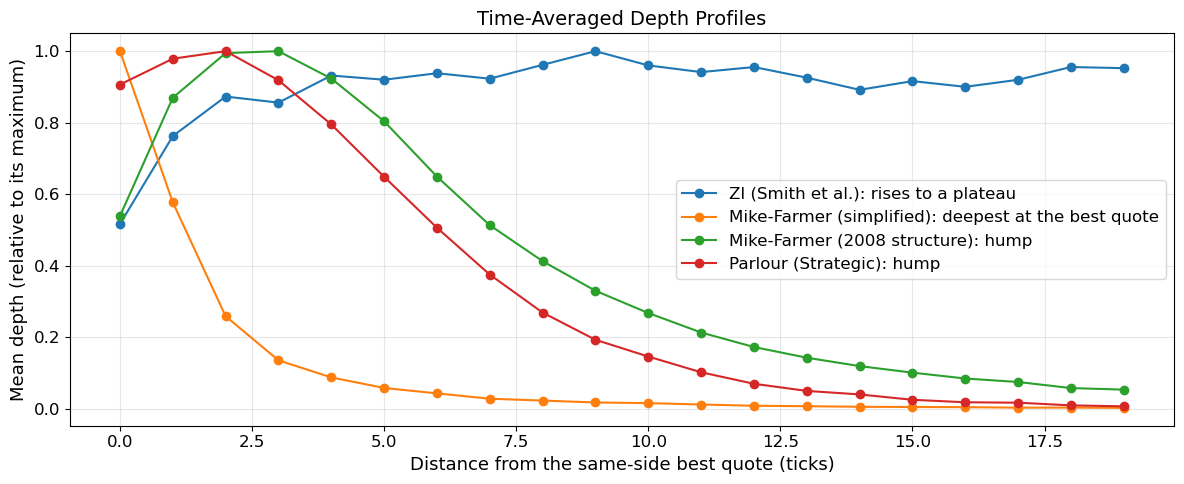


Models with a hump-shaped mean profile: Mike-Farmer (2008 structure), Parlour (Strategic)


In [5]:
depth_models = {
    'ZI (Smith et al.)': SmithFarmerModel(mu=1.0, lam=0.5, delta=0.1, price_range=50, initial_mid=10000),
    'Mike-Farmer (simplified)': MikeFarmerModel(mu=1.0, lam=3.0, delta=0.05, alpha_price=1.5, hurst=0.7,
                                                initial_mid=10000, size_mean=0.5, size_sigma=0.3),
    'Mike-Farmer (2008 structure)': MikeFarmer2008Model(initial_mid=10000),
    'Parlour (Strategic)': ParlourModel(arrival_rate=5.0, delta=0.05, initial_mid=10000),
}
labels = {'hump': 'hump', 'plateau': 'rises to a plateau', 'best quote': 'deepest at the best quote'}

fig, ax = plt.subplots(figsize=(12, 5))
humps = []
for name, model in depth_models.items():
    sim, _ = run_model(model, n_events=100_000, snapshot_interval=50)
    deltas, bid_depth, ask_depth = mean_depth_profile(sim.snapshots, n_ticks=20)
    profile = (bid_depth + ask_depth) / 2
    shape, rise, fall, peak = classify_depth_profile(profile)
    if shape == 'hump':
        humps.append(name)
    ax.plot(deltas, profile / profile.max(), 'o-', label=f'{name}: {labels[shape]}')
    print(f"{name:28s} depth at best quote {profile[0]:5.2f}; deepest level beyond it {profile[peak]:5.2f} "
          f"at {peak} tick{'s' if peak != 1 else ''} ({rise:+.0%}); far end {fall:.0%} below that "
          f"-> {labels[shape]}")
ax.set_xlabel('Distance from the same-side best quote (ticks)')
ax.set_ylabel('Mean depth (relative to its maximum)')
ax.set_title('Time-Averaged Depth Profiles')
ax.legend()
plt.tight_layout()
plt.show()

print("\nModels with a hump-shaped mean profile:", ', '.join(humps) if humps else 'none')

## 5. Concave Price Impact

From the paper (Section 4.6.1): in a study of the NYSE and American Stock Exchange, *"Hasbrouck (1991) found $\phi_m$ to be a concave function of $|\omega_x|$"* — the immediate price impact of a market order grows more slowly than its size.

For a single market order, the mechanical part of this impact is set by the book it walks into: it consumes the best quote, then the next level, and so on. If depth increases away from the quote, each extra lot moves the price less than the one before, so impact is concave; if depth decreases, impact is convex.

We measure the *virtual* impact in the ZI model: for each recorded snapshot, how far the mid-price would move if a buy market order of size $V$ arrived, without executing it. Averaging over snapshots, with orders that leave the price unchanged counted as zero impact, gives the mean impact curve. Its log-log slope is 1 for linear impact and 0.5 for a square-root law. We only use sizes that at least 90% of snapshots hold enough depth for.

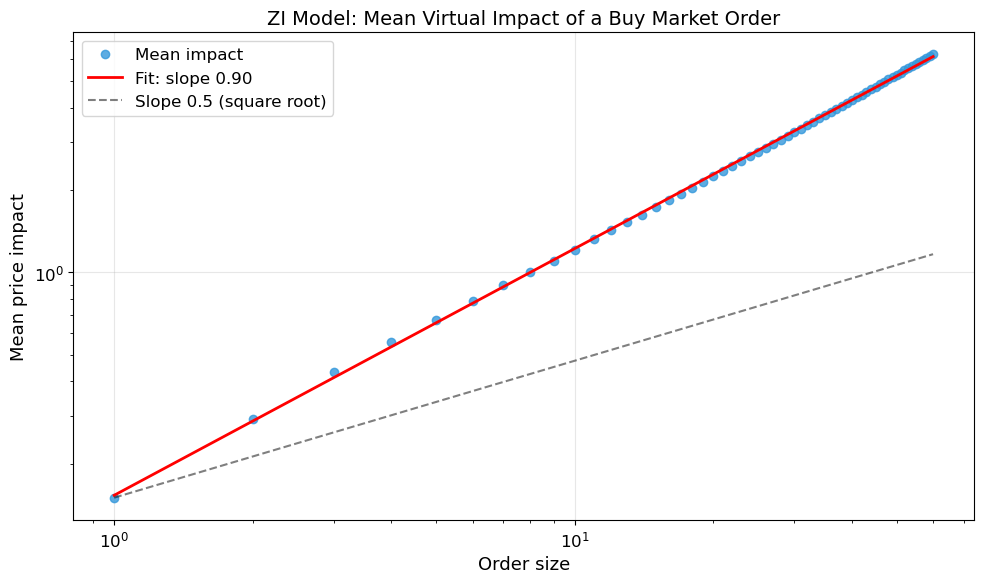

Sizes 1-60 lots, averaged over 2,000 snapshots
Log-log slope of mean impact: 0.90 (linear = 1.0, square-root law = 0.5) -> mildly concave


In [6]:
sim_zi, _ = run_model(SmithFarmerModel(mu=1.0, lam=0.5, delta=0.1, price_range=50, initial_mid=10000),
                      n_events=500_000, snapshot_interval=250)
sizes, mean_impact = mean_virtual_impact(sim_zi.snapshots, np.arange(1, 61))

fig, ax = plt.subplots(figsize=(10, 6))
plot_price_impact(sizes, mean_impact, ax=ax)
ax.set_title('ZI Model: Mean Virtual Impact of a Buy Market Order')
plt.tight_layout()
plt.show()

slope = fit_loglog_slope(sizes, mean_impact)
if slope < 0.75:
    shape = 'strongly concave'
elif slope < 0.95:
    shape = 'mildly concave'
elif slope <= 1.05:
    shape = 'roughly linear'
else:
    shape = 'convex'
print(f"Sizes 1-{sizes.max():.0f} lots, averaged over {len(sim_zi.snapshots):,} snapshots")
print(f"Log-log slope of mean impact: {slope:.2f} (linear = 1.0, square-root law = 0.5) -> {shape}")

This curvature comes only from the shape of the average ZI book. The empirical square-root law of Section 4.6 is a broader statement: Gabaix et al. (2006), for example, reported that the mean mid-price log return over 15-minute windows grew as the square root of the *trade imbalance size*, the net volume of market orders in the window. A static book cannot explain that on its own. Notebook 06 varies the depth profile directly to see how far the mechanical effect can go.

## 6. Heavy-Tailed Return Distribution

From the paper (Section 4.7.1): *"Over all timescales ranging from seconds to days, unconditional distributions of mid-price returns have been reported to display tails that are heavier than a normal distribution (i.e. they have positive excess kurtosis)."* At the shortest timescales the tails have been reported to follow a power law with exponent $\alpha \approx 3$, *"thereby earning the monicker 'the inverse cubic law of returns'."*

We draw Student-$t$ returns with 3 degrees of freedom, whose tail exponent is exactly 3, and check that the Hill estimator recovers it.

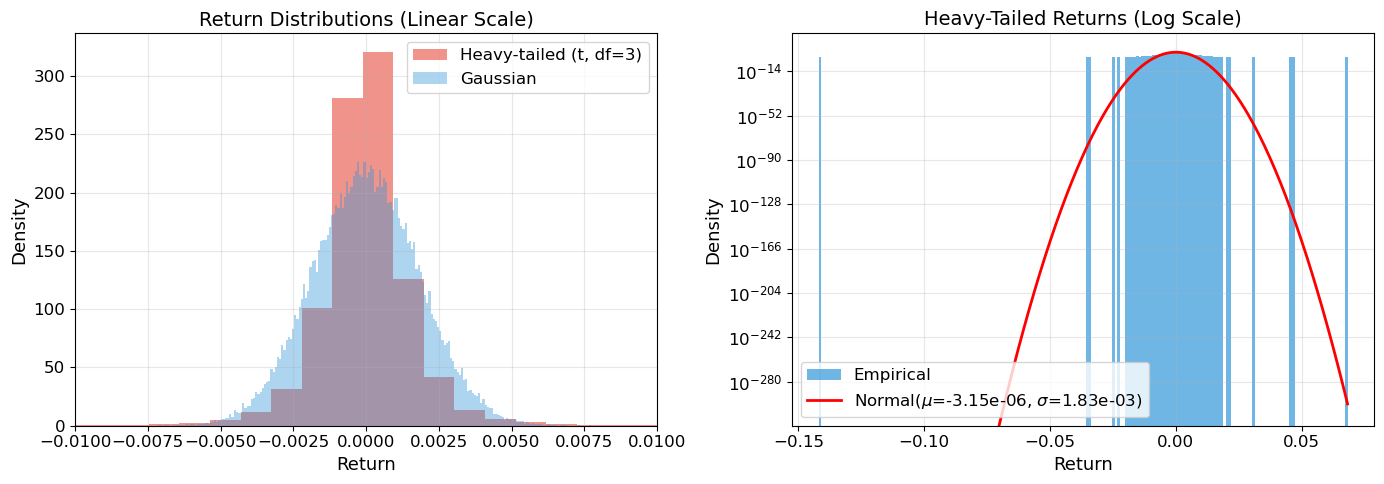

Hill estimate of the tail index: 2.91 (true value 3)
Consistent with the inverse cubic law used to generate the data.
Sample excess kurtosis: 792.9. A t(3) distribution has infinite kurtosis, so this number is large and unstable from sample to sample.


In [7]:
heavy_returns = rng.standard_t(df=3, size=50000) * 0.001
gaussian_returns = rng.normal(0, heavy_returns.std(), size=50000)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(heavy_returns, bins=200, density=True, alpha=0.6, color='#e74c3c', label='Heavy-tailed (t, df=3)')
axes[0].hist(gaussian_returns, bins=200, density=True, alpha=0.4, color='#3498db', label='Gaussian')
axes[0].set_xlabel('Return')
axes[0].set_ylabel('Density')
axes[0].set_title('Return Distributions (Linear Scale)')
axes[0].legend()
axes[0].set_xlim(-0.01, 0.01)

plot_return_distribution(heavy_returns, n_bins=200, ax=axes[1])
axes[1].set_title('Heavy-Tailed Returns (Log Scale)')

plt.tight_layout()
plt.show()

alpha_hill = hill_estimator(heavy_returns)
print(f"Hill estimate of the tail index: {alpha_hill:.2f} (true value 3)")
print("Consistent with the inverse cubic law used to generate the data." if abs(alpha_hill - 3) < 0.5 else
      "The Hill estimate is more than 0.5 away from the true tail index.")
print(f"Sample excess kurtosis: {stats.kurtosis(heavy_returns):.1f}. A t(3) distribution has infinite "
      f"kurtosis, so this number is large and unstable from sample to sample.")

## 7. Volatility Clustering

From the paper (Section 4.7.2): *"Time series of absolute or square mid-price returns have been reported to display long memory ... over timescales of weeks or even months."* Large moves tend to be followed by large moves, and small by small.

We simulate a GARCH(1,1) process, the textbook model of volatility clustering, and look at the autocorrelation of returns and of absolute returns. Dashed lines mark the 95% band for white noise of the same length.

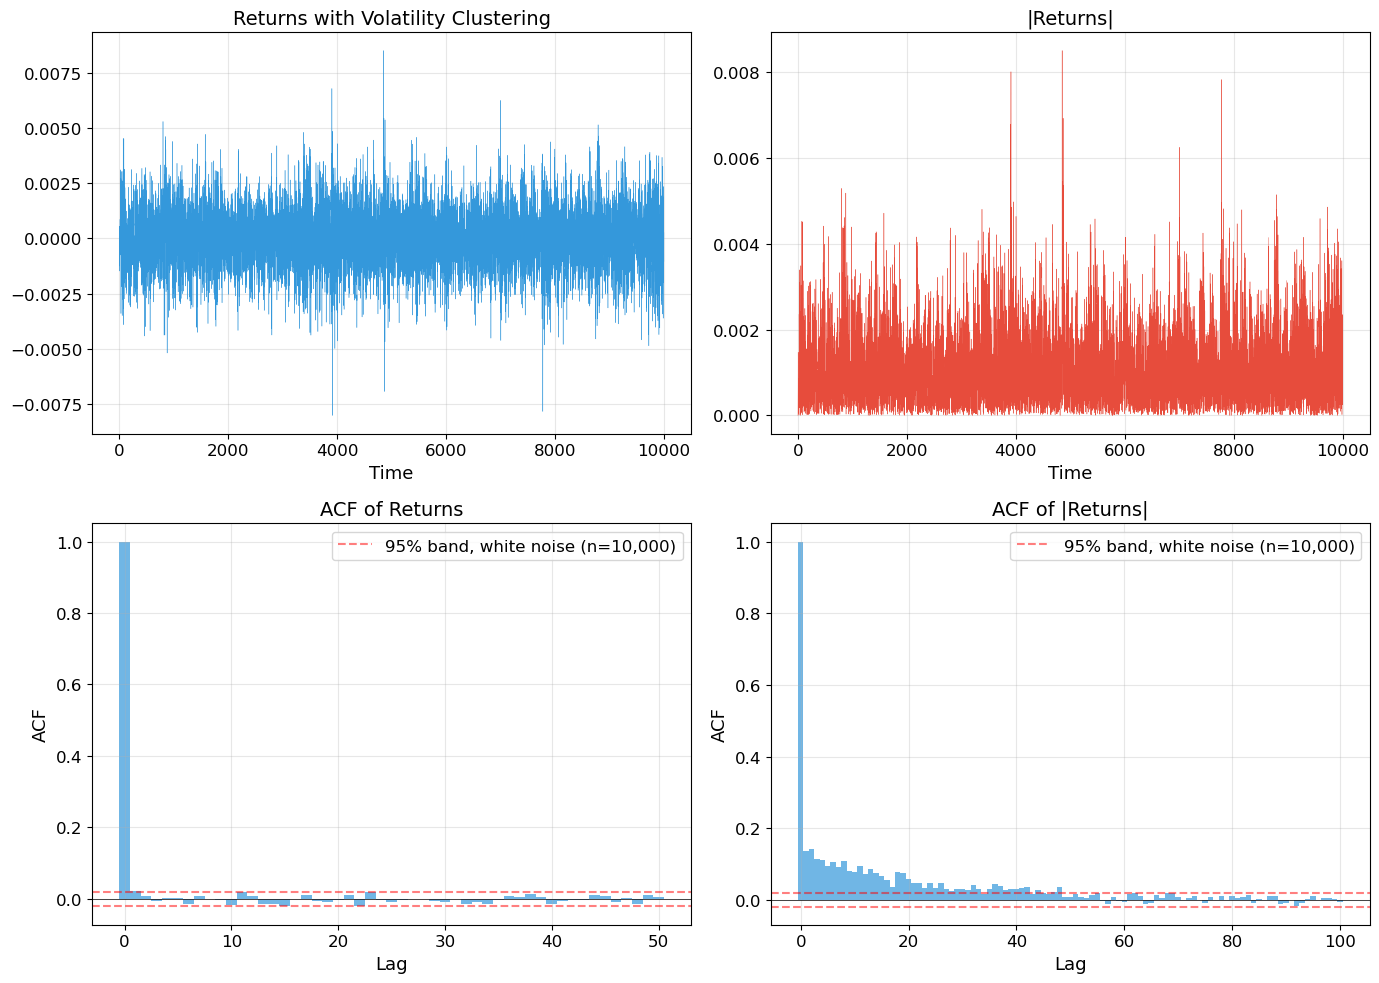

Returns: 4% of lags 1-50 fall outside the white-noise band (about 5% expected by chance)
|Returns|: ACF 0.136 at lag 1, 0.077 at lag 10, 0.008 at lag 50 (band ±0.020)
Returns are close to uncorrelated while their magnitudes stay correlated for many lags: volatility clustering.


In [8]:
n = 10000
sigma = np.zeros(n)
returns_vc = np.zeros(n)
sigma[0] = 0.001

alpha_garch, beta_garch, omega = 0.1, 0.85, 1e-7
for i in range(1, n):
    sigma[i] = np.sqrt(omega + alpha_garch * returns_vc[i-1]**2 + beta_garch * sigma[i-1]**2)
    returns_vc[i] = rng.normal(0, sigma[i])

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes[0, 0].plot(returns_vc, linewidth=0.3, color='#3498db')
axes[0, 0].set_title('Returns with Volatility Clustering')
axes[0, 0].set_xlabel('Time')
axes[0, 1].plot(np.abs(returns_vc), linewidth=0.3, color='#e74c3c')
axes[0, 1].set_title('|Returns|')
axes[0, 1].set_xlabel('Time')

acf_r = compute_acf(returns_vc, max_lag=50)
plot_acf(acf_r, title='ACF of Returns', ax=axes[1, 0], n=n)
acf_abs = compute_volatility_clustering(returns_vc, max_lag=100)
plot_acf(acf_abs, title='ACF of |Returns|', ax=axes[1, 1], n=n)

plt.tight_layout()
plt.show()

band = white_noise_band(n)
outside_r = np.mean(np.abs(acf_r[1:51]) > band)
print(f"Returns: {outside_r:.0%} of lags 1-50 fall outside the white-noise band (about 5% expected by chance)")
print(f"|Returns|: ACF {acf_abs[1]:.3f} at lag 1, {acf_abs[10]:.3f} at lag 10, {acf_abs[50]:.3f} at lag 50 "
      f"(band ±{band:.3f})")
if outside_r <= 0.1 and acf_abs[10] > band:
    print("Returns are close to uncorrelated while their magnitudes stay correlated for many lags: "
          "volatility clustering.")
else:
    print("This sample does not show the textbook pattern of uncorrelated returns with correlated magnitudes.")

## 8. Long Memory, and How Hard It Is to Measure

From the paper (Section 3.10.2): *"Intuitively, a time series has long memory if values from the present are correlated with values in the distant future. The study of long-memory processes involves considerable challenges, and caution is needed when applying standard statistical techniques to data with long memory."*

A common summary is the Hurst exponent $H$: 0.5 for no memory, above 0.5 for persistence. We estimate it by rescaled range (R/S) analysis for white noise, for the GARCH returns, and for their absolute values.

In [9]:
H_returns = compute_hurst_rs(returns_vc)
H_abs_returns = compute_hurst_rs(np.abs(returns_vc))
H_white = compute_hurst_rs(rng.normal(0, 1, n))

print("Hurst exponent estimates (R/S method):")
print(f"  White noise (reference): H = {H_white:.3f}")
print(f"  GARCH returns:           H = {H_returns:.3f}")
print(f"  GARCH |returns|:         H = {H_abs_returns:.3f}")
if H_abs_returns > H_white + 0.1:
    print(f"\nR/S finds strong persistence in |returns|. But GARCH(1,1) has short memory: shocks to the "
          f"variance decay geometrically, at rate alpha + beta = {alpha_garch + beta_garch:.2f} per step. "
          f"In a finite sample, R/S cannot tell strong short memory from genuine long memory, which is "
          f"one reason for the caution the paper urges.")
else:
    print("\nR/S finds little persistence in |returns| beyond the white-noise reference.")

Hurst exponent estimates (R/S method):
  White noise (reference): H = 0.495
  GARCH returns:           H = 0.525
  GARCH |returns|:         H = 0.720

R/S finds strong persistence in |returns|. But GARCH(1,1) has short memory: shocks to the variance decay geometrically, at rate alpha + beta = 0.95 per step. In a finite sample, R/S cannot tell strong short memory from genuine long memory, which is one reason for the caution the paper urges.


## 9. Long Memory in Order Signs

From the paper (Section 4.7.3): *"The time series constructed by assigning the value +1 to incoming buy orders and −1 to incoming sell orders has been reported to exhibit long memory"* on the Paris Bourse, the NYSE and the Shenzhen Stock Exchange.

We generate long-memory signs by taking the sign of fractional Gaussian noise with $H = 0.75$. Theory gives two checks. The lag-1 autocorrelation of the signs is $\frac{2}{\pi}\arcsin\gamma(1)$, where $\gamma(1) = 2^{2H-1} - 1$ is the lag-1 autocorrelation of the noise. At long lags the autocorrelation decays like $k^{2H-2}$, a slope of $-0.5$ on a log-log plot.

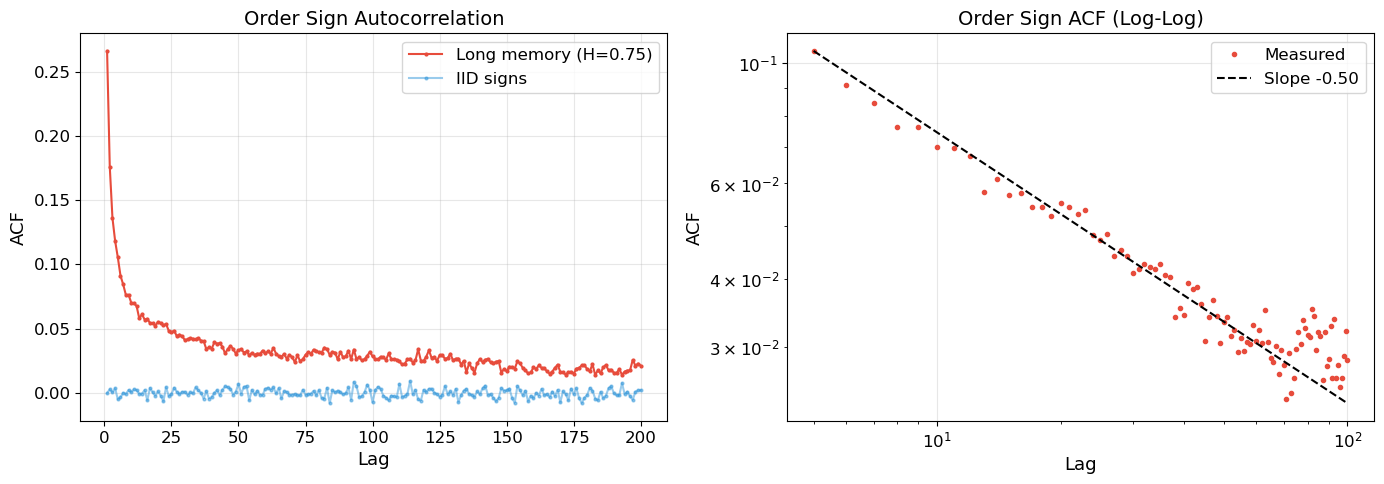

Lag-1 sign autocorrelation: 0.266 (theory 0.272)
Log-log slope over lags 5-100: -0.42 (theory -0.50)


R/S Hurst exponent of the signs: 0.720 (input H = 0.75)
Both checks agree with theory within tolerance: the signs carry the long memory that was built in.
Notebook 06 asks where such memory could come from in real markets.


In [10]:
H = 0.75
n_signs = 100_000
order_signs = np.where(_generate_fractional_noise(n_signs, H=H, rng=rng) >= 0, 1, -1)
iid_signs = rng.choice([-1, 1], size=n_signs)

acf_long = compute_order_sign_acf(order_signs, max_lag=200)
acf_iid = compute_order_sign_acf(iid_signs, max_lag=200)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(range(1, 201), acf_long[1:], 'o-', markersize=2, color='#e74c3c', label=f'Long memory (H={H})')
axes[0].plot(range(1, 201), acf_iid[1:], 'o-', markersize=2, color='#3498db', alpha=0.5, label='IID signs')
axes[0].set_xlabel('Lag')
axes[0].set_ylabel('ACF')
axes[0].set_title('Order Sign Autocorrelation')
axes[0].legend()

lags = np.arange(5, 101)
slope = fit_loglog_slope(lags, acf_long[5:101])
axes[1].loglog(lags, acf_long[5:101], 'o', markersize=3, color='#e74c3c', label='Measured')
axes[1].loglog(lags, acf_long[5] * (lags / 5.0) ** (2 * H - 2), 'k--', label=f'Slope {2 * H - 2:.2f}')
axes[1].set_xlabel('Lag')
axes[1].set_ylabel('ACF')
axes[1].set_title('Order Sign ACF (Log-Log)')
axes[1].legend()
plt.tight_layout()
plt.show()

lag1_theory = 2 / np.pi * np.arcsin(2 ** (2 * H - 1) - 1)
print(f"Lag-1 sign autocorrelation: {acf_long[1]:.3f} (theory {lag1_theory:.3f})")
print(f"Log-log slope over lags 5-100: {slope:.2f} (theory {2 * H - 2:.2f})")
print(f"R/S Hurst exponent of the signs: {compute_hurst_rs(order_signs):.3f} (input H = {H})")
if abs(acf_long[1] - lag1_theory) < 0.03 and abs(slope - (2 * H - 2)) < 0.25:
    print("Both checks agree with theory within tolerance: the signs carry the long memory that was built in.")
    if slope < 2 * H - 2:
        print("The fitted slope is steeper than theory, as expected: sample autocorrelations of "
              "long-memory series are biased downward at long lags.")
else:
    print("At least one check disagrees with theory by more than its tolerance.")
print("Notebook 06 asks where such memory could come from in real markets.")

## 10. Negative Short-Lag Autocorrelation and the Bid-Ask Bounce

From the paper (Section 4.7.4): *"Several studies have reported that return series lacked significant autocorrelation, except for weakly negative autocorrelation on very short timescales."*

One source of short-lag reversal is the bid-ask bounce (Roll 1984): transaction prices alternate between the bid and the ask depending on which side initiated each trade, even when the mid-price does not move. The bounce lives in *transaction* prices, so we measure trade-price changes and mid-price changes separately, in the same ZI simulation, sampling both at each trade.

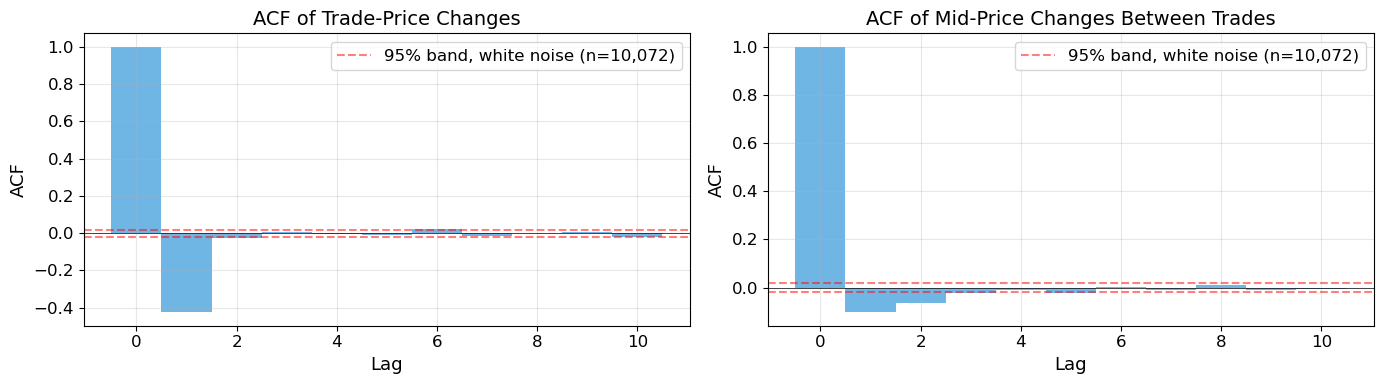

10,073 trades; 95% white-noise band ±0.020
Lag-1 ACF of trade-price changes:          -0.425
Lag-1 ACF of mid-price changes (same times): -0.103
Trade prices reverse much more strongly than the mid-price: the bid-ask bounce. It is a mechanical feature of trading at the quotes, not evidence of predictable mid-price moves.


In [11]:
_, df_zi = run_model(SmithFarmerModel(mu=1.0, lam=0.5, delta=0.1, price_range=50, initial_mid=10000),
                     n_events=1_000_000)
trades = df_zi[(df_zi['event_type'] == 'market') & (df_zi['n_fills'] > 0)].dropna(subset=['mid_price'])
trade_prices = np.array([prices[-1] for prices in trades['fill_prices']], dtype=float)
mid_at_trades = trades['mid_price'].to_numpy(dtype=float)

d_trade = np.diff(trade_prices)
d_mid = np.diff(mid_at_trades)
acf_trade = compute_acf(d_trade, max_lag=10)
acf_mid = compute_acf(d_mid, max_lag=10)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(acf_trade, title='ACF of Trade-Price Changes', ax=axes[0], n=len(d_trade))
plot_acf(acf_mid, title='ACF of Mid-Price Changes Between Trades', ax=axes[1], n=len(d_mid))
plt.tight_layout()
plt.show()

band = white_noise_band(len(d_trade))
print(f"{len(trade_prices):,} trades; 95% white-noise band ±{band:.3f}")
print(f"Lag-1 ACF of trade-price changes:          {acf_trade[1]:+.3f}")
print(f"Lag-1 ACF of mid-price changes (same times): {acf_mid[1]:+.3f}")
if acf_trade[1] < -band and acf_trade[1] < acf_mid[1] - band:
    print("Trade prices reverse much more strongly than the mid-price: the bid-ask bounce. "
          "It is a mechanical feature of trading at the quotes, not evidence of predictable mid-price moves.")
else:
    print("Trade prices do not reverse more strongly than the mid-price in this sample.")

## Summary: Stylized Facts and Where They Are Discussed

| # | Stylized fact | Paper section | Key reference |
|---|--------------|---------------|---------------|
| 1 | Heavy-tailed order sizes | 4.1 | Maslov and Mills (2001) |
| 2 | Round-number clustering | 4.1 | Challet and Stinchcombe (2001), Mu et al. (2009) |
| 3 | Power-law relative prices | 4.2 | Bouchaud et al. (2002), Zovko and Farmer (2002) |
| 4 | Hump-shaped depth profile | 4.4 | Bouchaud et al. (2002) |
| 5 | Concave price impact | 4.6 | Hasbrouck (1991), Lillo et al. (2003) |
| 6 | Heavy-tailed returns | 4.7.1 | Gopikrishnan et al. (1998) |
| 7 | Volatility clustering | 4.7.2 | Cont (2001) |
| 8 | Long memory | 3.10.2 | Beran (1994) |
| 9 | Long memory in order signs | 4.7.3 | Lillo and Farmer (2004) |
| 10 | Short-lag reversal, bid-ask bounce | 4.7.4 | Roll (1984) |

**Next:** Notebook 05 compares how well the three models reproduce these facts.